# GuardKit Evidence · 课程交付 Notebook（§1.6 允许的交付形态）

> **一句话**：香港中小企业财务收到可疑付款消息 → 打分 → 判决卡（分数 + 命中规则 + 官方原文依据）→ 高危升级人工。**永不自动拦截。**
>
> 本 notebook 是仓库四条命令的**分步等价物**：按顺序跑完 = 完整走一遍 `源数据 → 建库 → 打分 → 检索 → 判决落库 → 业务 SQL → 评估` 的路径（§1.6 Integration and lineage）。
> 逻辑实现在 `src/*.py`（已由 tests 守门），这里只做**调用与讲解**，避免两份实现漂移。
> 仅需 Python 3 标准库（sqlite3 含 FTS5）。

In [1]:
# ── 环境准备：让 notebook 能导入仓库里的模块 ─────────────────────────────
import sys, sqlite3, json
from pathlib import Path
sys.path.insert(0, '.')      # 仓库根 → engine/scorer.py（pinned 引擎，只读）
sys.path.insert(0, 'src')    # src/    → build_db（建库）/ run_demo（打分+检索+判决卡）/ textproc（文本处理+PII）
import build_db, run_demo, textproc
from engine import scorer    # ← 打分函数 make_scorer 从这里来（不修改，见文件头声明）

DB = Path('guardkit_evidence.sqlite')            # 唯一产品数据库（单文件，零配置）
conn = sqlite3.connect(DB)
conn.execute("SELECT 1 FROM evidence_fts LIMIT 1")   # FTS5 全文检索可用性检查（SQLite 内置，无需安装）
print('环境 OK：Python', sys.version.split()[0], '| SQLite', sqlite3.sqlite_version, '| FTS5 可用')

环境 OK：Python 3.14.7 | SQLite 3.53.2 | FTS5 可用


## §1 建库：三路数据进一个 SQLite（8 张业务表 + 1 张检索虚表）

**为什么拆 8 张表**：每个稳定业务概念一张表（机构/文档/段落/消息/判决/规则/正则/证据连接），同一事实只存一处，表间用外键引用——"哪条判决引用了哪段官方原文"是数据库里的**硬约束**（Element 6 / Integration）。
`build_db.main()` 从 `data/*.jsonl`（105 条真实消息 + 25 份证据文档）与种子灌库，末尾打印硬门槛自检（≥20 文档 / ≥50 短文本）。

In [2]:
# ── 建库：删旧表 → 建 8 张业务表 + 1 张 FTS5 虚表 → 灌三路数据 → 硬门槛自检 ──
# 三路数据：① data/*.jsonl（105 条真实消息 + 25 份证据文档）② seed_evidence.json（2 份逐字引用种子）
#           ③ 内嵌 3 条演示消息；白名单正则同时从 pinned 引擎投影成 rule_patterns 表（规则即数据）
build_db.main()

OK -> guardkit_evidence.sqlite
  institutions=9 rules=3 rule_patterns=7
  messages=108（含 3 条演示）evidence_documents=27 evidence_passages=34
  PII 扫描：证据段落脱敏 0 处；消息疑似命中 2 处（只计数，文本逐字保留）
  硬门槛：文档 ≥20 ✅（27 份）；短文本 ≥50 ✅（108 条）


In [3]:
# ── 查看建出来的结构：每张表行数 + 外键关系（血缘的骨架） ──────────────────
tables = [r[0] for r in conn.execute("SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%' ORDER BY name")]
for t in tables:
    n = conn.execute('SELECT COUNT(*) FROM ' + t).fetchone()[0]   # 每张表的行数
    print(f'{t:22s} {n:>4} 行')
print()
print('外键：')   # 外键 = 表之间的引用线；判决↔证据的连接就在最后两行
for t in ('evidence_documents','evidence_passages','rules','rule_patterns','verdicts','verdict_evidence'):
    for f in conn.execute('PRAGMA foreign_key_list(' + t + ')'):
        print(f'  {t}.{f[3]} → {f[2]}.{f[4]}')

evidence_documents       27 行
evidence_fts             34 行
evidence_fts_config       1 行
evidence_fts_content     34 行
evidence_fts_data         6 行
evidence_fts_docsize     34 行
evidence_fts_idx          4 行
evidence_passages        34 行
institutions              9 行
messages                108 行
rule_patterns             7 行
rules                     3 行
verdict_evidence          0 行
verdicts                  0 行

外键：
  evidence_documents.institution_id → institutions.id
  evidence_passages.doc_id → evidence_documents.doc_id
  rules.institution_id → institutions.id
  rule_patterns.rule_id → rules.id
  verdicts.verdict_rule_id → rules.id
  verdicts.message_id → messages.id
  verdict_evidence.passage_id → evidence_passages.id
  verdict_evidence.verdict_id → verdicts.id


## §1.5 设计图：ERD 与架构/血缘视图（§2.4 交付物 "Design artefacts"）

ERD 讲**静态结构**（9 张表怎么连），血缘图讲**数据怎么流动**（来源→摄取→存储→判决→输出，每一跳标着背书字段）。
两张图的 mermaid 源码在 `docs/design.md`（GitHub 可直接渲染）；本 cell 直接显示已渲染的 PNG。
右下"可验证性"框是关键：血缘不是口头声明——文档级 URL+日期+hash 可比对、判决级一条 SQL 溯源、库级逐字节可复现。

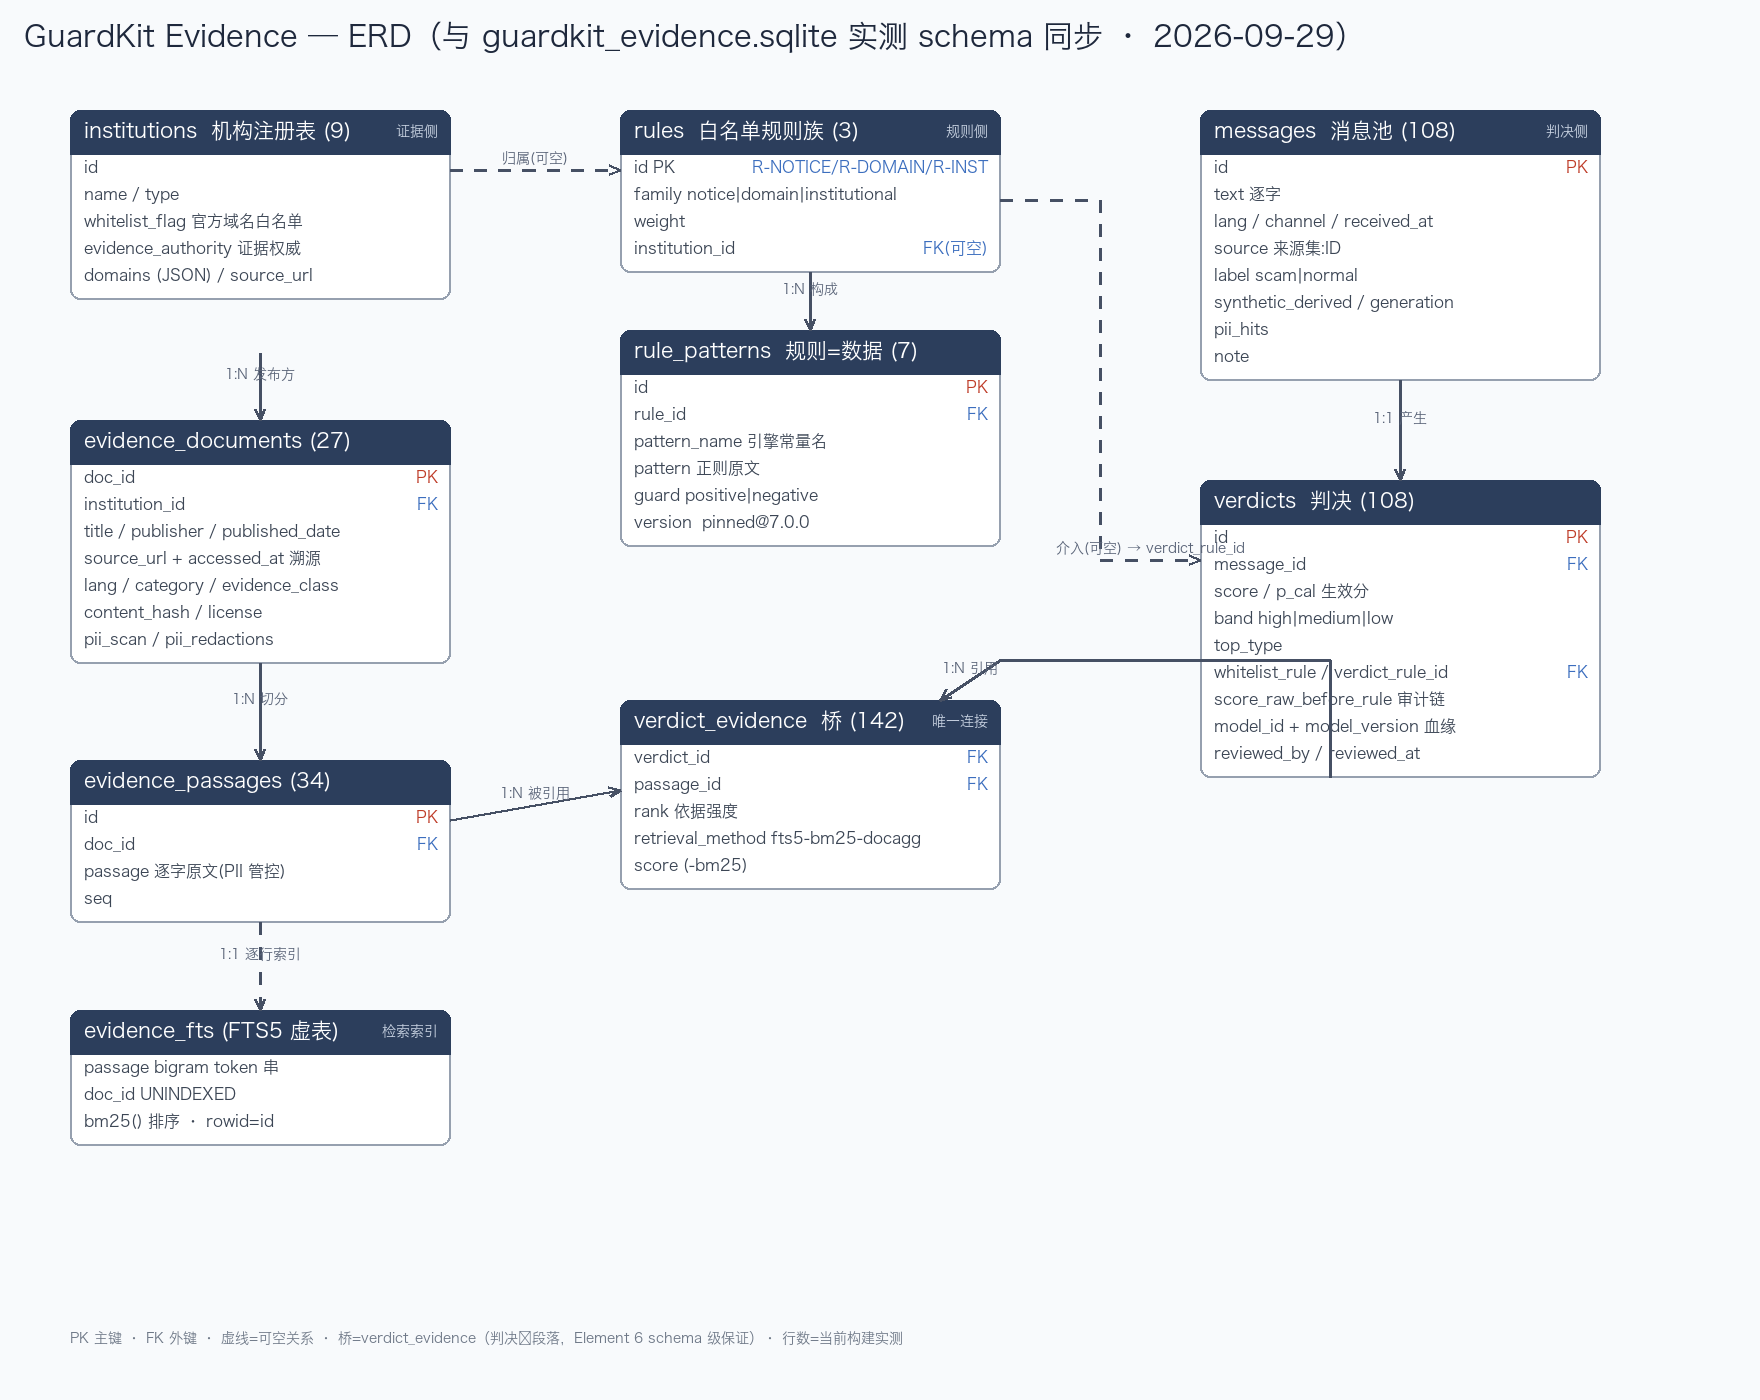

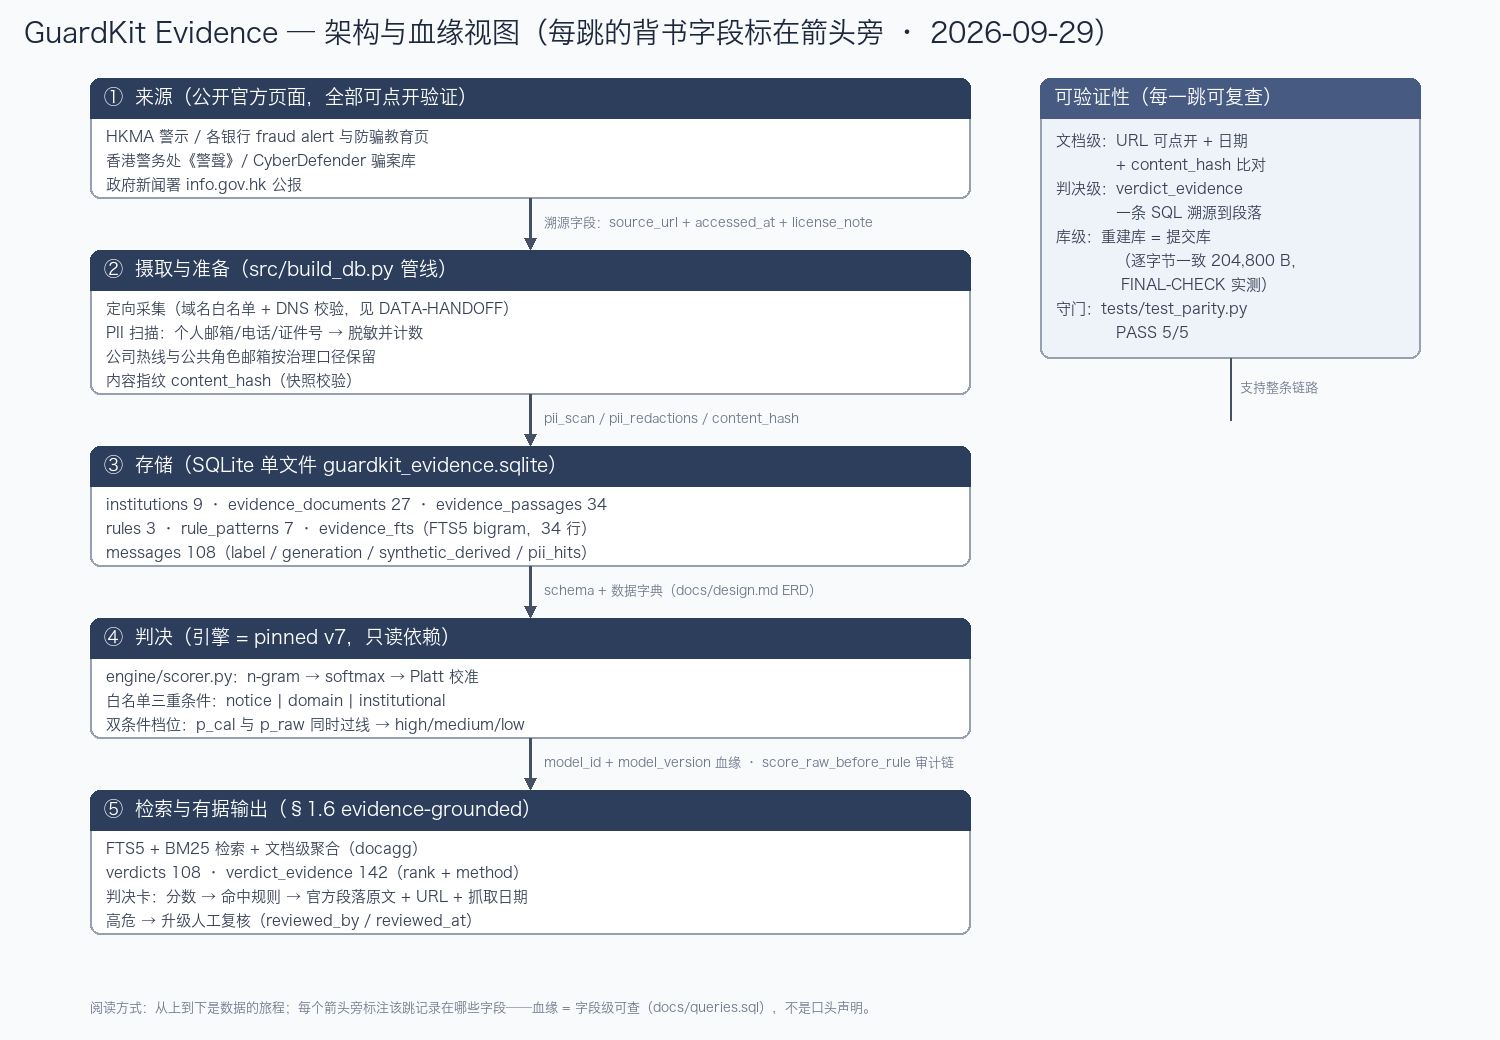

In [4]:
# ── 设计图（§2.4 交付物 "Design artefacts"）：ERD = 静态结构，血缘图 = 数据怎么流动 ──
# mermaid 源码在 docs/design.md（GitHub 自动渲染）；这里显示已渲染的 PNG
# 右下"可验证性"框：文档级 URL+hash 比对 / 判决级 SQL 溯源 / 库级逐字节复现 / parity 守门
from IPython.display import Image
display(Image(filename='docs/assets/erd.png'))
display(Image(filename='docs/assets/lineage.png'))

## §2 打分：冻结引擎 + 白名单 + 审计链

**引擎四步**：① 文本切 1/2/3 字碎片（中文无空格，按字切免词典）② 查模型权重 ③ softmax 出概率 ④ Platt 校准 → `p_cal`（校准分）与 `p_raw`（原始分）。
**白名单三族（全部命中才放行）**：反诈提示 / 官方域名 / 机构通知——正则在 `rule_patterns` 表（规则即数据，带版本）。
**审计链**：压档前原始分存 `score_raw_before_rule`，"规则压了多少分"永远可查。

In [5]:
# ── 对 MSG-001（冒充供应商换账户）单条打分，看引擎到底输出了什么 ─────────
conn.close(); conn = sqlite3.connect(DB)
msg = conn.execute("SELECT id, text FROM messages WHERE id='MSG-001'").fetchone()
s = run_demo.SCORE(msg[1])                      # 引擎打分：返回 (预测, 各类概率, 校准分, 原始分)
pred, probs, p_cal, p_raw = s[0], s[1], s[2], s[3]
wl = run_demo.whitelist_rule_of(scorer.norm_text(msg[1]))   # 与引擎同口径的白名单判定（三族，全中才放行）
band_before = run_demo.band_of(p_cal, p_raw)    # 双条件判档：p_cal 与 p_raw 同时过线才算高危
print(f'{msg[0]} 引擎原始输出: pred={pred}  p_raw={p_raw:.4f}  p_cal={p_cal:.4f}  档位={band_before}  白名单={wl}')

MSG-001 引擎原始输出: pred=scam  p_raw=0.9861  p_cal=1.0000  档位=high  白名单=None


In [6]:
# ── 三条演示消息：白名单压档前后对照（审计链的意义所在） ─────────────────
# MSG-002 命中机构白名单：分数被压到可疑档以下，但"压之前的原始分"保留在 score_raw_before_rule 字段
# MSG-001/003 不命中白名单：分数原样生效
for mid in ('MSG-001','MSG-002','MSG-003'):
    m = conn.execute("SELECT id, text FROM messages WHERE id=?", (mid,)).fetchone()
    s = run_demo.SCORE(m[1]); p_raw, p_cal = s[3], s[2]
    wl = run_demo.whitelist_rule_of(scorer.norm_text(m[1]))
    raw_before = p_raw                          # 规则介入前的引擎原始分
    if wl:                                      # 白名单压档：与引擎内部同规则，压到可疑档以下
        p_raw = min(p_raw, run_demo.MODEL['bands']['mid'] - 0.01)
        p_cal = min(p_cal, run_demo.MODEL['bands']['mid'] - 0.01)
    band = run_demo.band_of(p_cal, p_raw)       # 压档后重新判档
    print(f'{mid}: 原始 p_raw={raw_before:.4f} → 生效 {p_raw:.4f} | 白名单={wl} | 档位={band}')

MSG-001: 原始 p_raw=0.9861 → 生效 0.9861 | 白名单=None | 档位=high
MSG-002: 原始 p_raw=0.3400 → 生效 0.3400 | 白名单=institutional | 档位=low
MSG-003: 原始 p_raw=0.7631 → 生效 0.7631 | 白名单=None | 档位=high


## §3 检索：FTS5 + BM25 + 文档级聚合

**中文无空格** → 按字切 **bigram** 建索引；排序用 **BM25**（词在段内出现越多越相关 × 词越稀缺越有区分力），权重来自标准算法而非手调常数。
**文档级聚合（docagg）**：按"整份通告"聚合竞争，防止样板话术密集的短通告霸榜。
**不用 embedding**：课程原话 *"when they add justified value"*——本场景精确术语命中，词面匹配可解释、可复现、零依赖。
**检索不到**：如实显示无依据，不硬凑。

In [7]:
# ── 检索演示：换账户类消息 → 从 34 段官方文字里找依据 ───────────────────
# fts_query()：把消息切成字符 bigram 再用 OR 连接（裸空格是隐式 AND，几乎必然零命中）
# SQL 内完成 MATCH + bm25 排序（标准公式，无手调权重）；此处直接看前 3 名
q = textproc.fts_query('我哋公司換咗收款戶口，請今日內轉去新戶口')
rows = conn.execute("""SELECT d.doc_id, d.title, bm25(evidence_fts) AS rel
    FROM evidence_fts f JOIN evidence_passages p ON p.id = f.rowid
    JOIN evidence_documents d ON d.doc_id = p.doc_id
    WHERE evidence_fts MATCH ? ORDER BY rel LIMIT 3""", (q,)).fetchall()
print('查询 token（bigram OR 串，前 80 字符）：', q[:80], '...')
for r in rows:
    print(f'  bm25={r[2]:8.3f} {r[0]:18s} 《{r[1][:30]}》')   # bm25 越负越相关（FTS5 约定）

查询 token（bigram OR 串，前 80 字符）： 今日 OR 內轉 OR 公司 OR 去新 OR 口請 OR 司換 OR 咗收 OR 哋公 OR 我哋 OR 戶口 OR 換咗 OR 收款 OR 新戶 OR 日內 ...
  bm25=  -4.335 EV018              《借出戶口代公司客戶轉資，以賺取佣金，但先要以個人名義向財務公》
  bm25=  -3.721 HKPF-BEC-2026      《商業電郵騙案｜如何避開商業電郵騙案？5大常見作案手法大公開》
  bm25=  -2.684 HKPF-BEC-2026      《商業電郵騙案｜如何避開商業電郵騙案？5大常見作案手法大公開》


## §4 全流程：判决落库 + 判决卡（108 判决 = 84 有证据 + 12 白名单 + 12 如实无检索）

In [8]:
# ── 全流程：对库内 108 条消息逐条 打分→白名单→检索→判决与证据落库→出判决卡 ──
# 每条判决写 verdicts（含压档前原始分、命中规则外键）；
# 非白名单判决的证据命中写 verdict_evidence（rank + 检索方法 + 相关度）→ 可 SQL 溯源
run_demo.main()

已落库判决 108 条：高危 48 / 可疑 4 / 未识别 56；白名单放行 12 条；证据连接 142 条（verdict_evidence）

──────────────────────────────────────────────────────────────
判决卡 MSG-001  [2026-09-29 14:02]
──────────────────────────────────────────────────────────────
消息：May你好，我係恆達五金阿強。我哋公司換咗收款戶口，上個月嗰批貨尾數HK$85,000請今日…
来源：demo:written:MSG-001 | 渠道：whatsapp
风险分：1.00/1.00 ███████████████████
档位：高危   引擎：radar v7 (pinned snapshot @7.0.0)
为什么：
  · 引擎判别大类：冒充身份
  · 要求更改收款账户
  · 指定转入新银行账户
  · 制造限期压力（今日内/即将截止）
官方依据（可溯源，已落库 verdict_evidence）：
  「收到更改收款賬戶的通知時，若供應商聲稱更換付款賬戶，必須先聯絡對方已知舊有聯絡方式確認，…」
    —— 香港警務處《警聲》《商業電郵騙案｜如何避開商業電郵騙案？》 溯源：https://www.police.gov.hk/offbeat120/scam4/4-business-email-scams.html（抓取 2026-09-29）
  「公司應建立「雙重授權／付款核實制度」：即使訊息看似來自高層或供應商，也需要另一位高級員工…」
    —— 香港警務處《警聲》《商業電郵騙案｜如何避開商業電郵騙案？》 溯源：https://www.police.gov.hk/offbeat120/scam4/4-business-email-scams.html（抓取 2026-09-29）
建议动作：立即停止付款流程，按下方建议核实或升级
          升级：案件 V-MSG-001 已生成（附本卡），转人工复核
──────────────────────────────────────────────────────────────

────────────────

In [9]:
# ── 判决卡长什么样：用 MSG-001 现场渲染一张（HTML 内嵌显示） ───────────────
# 卡上三样东西：分数档位 + 为什么可疑 + 官方段落原文（带链接和抓取日期）
from IPython.display import HTML
msg = conn.execute("SELECT id, text, lang, channel, received_at, source, note FROM messages WHERE id='MSG-001'").fetchone()
s = run_demo.SCORE(msg[1]); p_cal = s[2]                       # 校准分即卡上的"风险分"
hits = run_demo.retrieve_evidence(conn, msg[1])                # FTS5+BM25+文档聚合检索官方依据
HTML(run_demo.CARD_CSS + run_demo.html_card(msg, p_cal, 'high', 'impersonation', None, hits))

## §5 代表性业务 SQL（§1.6 明文要求的可检验证据）

In [10]:
# ── 六组代表性业务 SQL（§1.6 最低证据："SQL queries that answer business questions"）──
# 从 docs/queries.sql 原文件逐条执行：溯源 / 评估交叉表 / 压档审计 / 规则数据 / 证据覆盖 / 过滤检索
sql = Path('docs/queries.sql').read_text(encoding='utf-8')
stmts = [s.strip() for s in sql.split(';') if 'SELECT' in s.upper()]   # 按 ; 切开，只留含 SELECT 的语句
print(f'共 {len(stmts)} 条查询，逐条执行：')
for i, st in enumerate(stmts, 1):
    title = [l.lstrip('- ') for l in st.splitlines() if l.strip().startswith('--')]   # 取注释里的标题
    cur = conn.execute(st)
    rows = cur.fetchall()
    print(f'\n── Q{i} {title[0][:46] if title else ""} → {len(rows)} 行（前 4 行）')
    for r in rows[:4]:
        print('   ', tuple(str(c)[:34] for c in r))

共 7 条查询，逐条执行：

── Q1 GuardKit Evidence · 代表性业务 SQL（对照课程 §1.6 "repre → 83 行（前 4 行）
    ('V-MSG-001', 'demo:written:MSG-001', '0.9861417214431051', '0.9999765501845932', '1', '收到更改收款賬戶的通知時，若供應商聲稱更換付款賬戶，必須先聯絡對方已', '商業電郵騙案｜如何避開商業電郵騙案？5大常見作案手法大公開', 'https://www.police.gov.hk/offbeat1', '2026-09-29')
    ('V-MSG-001', 'demo:written:MSG-001', '0.9861417214431051', '0.9999765501845932', '2', '公司應建立「雙重授權／付款核實制度」：即使訊息看似來自高層或供應商，', '商業電郵騙案｜如何避開商業電郵騙案？5大常見作案手法大公開', 'https://www.police.gov.hk/offbeat1', '2026-09-29')
    ('V-MSG-003', 'blind-set:blind-v12:W12-N16', '0.7631364159943819', '0.9761443516404129', '1', '當受害人想套現獲利，「假客服」會以不同藉口拖延，例如戶口被凍結，投資', '當受害人想套現獲利，「假客服」會以不同藉口拖延，例如戶口被凍結，投資', 'https://cyberdefender.hk/romance_s', '2026-09-25')
    ('V-N200-N06', 'blind-n200:N200-N06', '0.5816608316453087', '0.861136218019378', '1', '一個域名為 「hxxps[:]//carousell-hk[.]pr', '一個域名為 「hxxps[:]//carousell-hk[.]pr', 'https://www1.shacombank.com.hk/tch', '2026-09-26')

── Q2 ── Q2 · 业务问题：引擎判得准不准？期望标签 × 判决档位交叉表（exp

## §6 评估：期望 × 实际（诚实画能力边界）

漏报与误报逐条归因；已知局限（2025 新骗术召回缺口 84.2%）主动写进报告。

In [11]:
# ── 评估：期望标签（人工标注真值）× 系统档位 交叉表 ───────────────────────
# flagged = high/medium（拦截方向）；released = low（放行方向）
# scam→released 是漏报（逐条归因），normal→flagged 是误报——评估的诚实就在这两格
print('expected × observed：')
for r in conn.execute("""SELECT m.label, CASE WHEN v.band IN ('high','medium') THEN 'flagged' ELSE 'released' END, COUNT(*)
    FROM verdicts v JOIN messages m ON m.id=v.message_id WHERE m.label IS NOT NULL GROUP BY 1,2 ORDER BY 1,2"""):
    print('  ', r)
print('\n漏报明细（真骗局被放行）：')
for r in conn.execute("""SELECT v.id, m.lang, printf('%.3f', v.score) FROM verdicts v JOIN messages m ON m.id=v.message_id
    WHERE m.label='scam' AND v.band='low' ORDER BY v.score"""):
    print('  ', r)

expected × observed：
   ('normal', 'flagged', 12)
   ('normal', 'released', 53)
   ('scam', 'flagged', 40)
   ('scam', 'released', 3)

漏报明细（真骗局被放行）：
   ('V-WA-S02', 'en', '0.342')
   ('V-W12-S01', 'mixed', '0.378')
   ('V-pub-nz-2025-bec-03', 'en', '0.391')


## §7 复现性：同样输入必然重建出同一个库（外部复核实测逐字节一致）

In [12]:
# ── 一致性守门：pinned 快照完整性（engine/models 任何改动都会在这里失败） ──
# PASS 5/5 = 快照向量全对；本机若有 public-v7 仓还会追加训练侧逐位对拍
import subprocess
r = subprocess.run([sys.executable, 'tests/test_parity.py'], capture_output=True, text=True)
print(r.stdout, r.stderr)
print('exit =', r.returncode)   # 0 = 守门通过

PASS: 5/5 snapshot vectors match（pinned 快照完整性）
NOTE: 未找到 public-v7 仓（/Users/zhanjianli/Desktop/MAIB7050/public-v7），跳过训练侧逐位对拍（包内快照守门已通过）
 
exit = 0


---
**等价四条命令**：`python3 src/build_db.py` → `python3 src/run_demo.py` → `python3 tests/test_parity.py` → `sqlite3 guardkit_evidence.sqlite < docs/queries.sql`
延伸阅读：`docs/design.md`（ERD+血缘）· `docs/theory-primer.md`（原理）· `docs/walkthrough.md`（答辩走讲）。